In [1]:
import hashlib
import os
import platform
import uuid
import sys

# 修改为自己的学号
STUDENT_ID = 20244080215
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

# 把字符串写在同一行，或者用括号拼接
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")
print(f"[Python] {sys.version.split()[0]}")


[Conda 环境] base
[学号] 20244080215
[机器指纹] cfe9c53742420697
[RUN_ID] 20244080215-cfe9c53742420697
[Python] 3.13.16


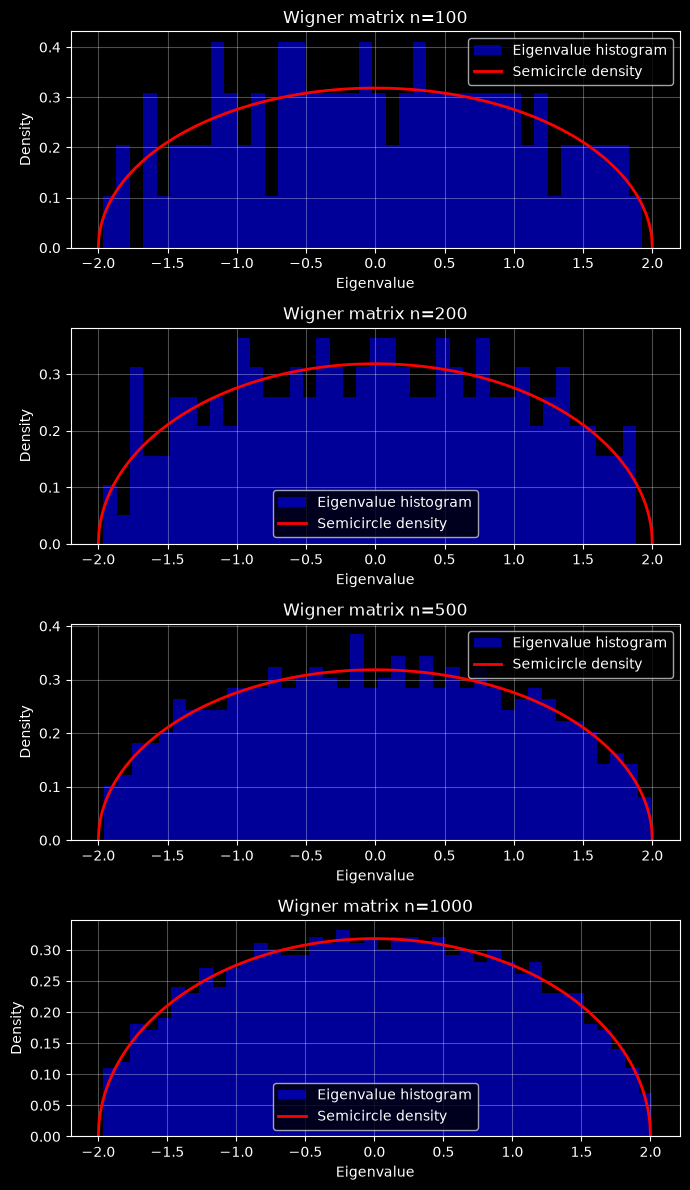

In [3]:
import numpy as np
import matplotlib.pyplot as plt

def wigner_density(x):
    res = np.zeros_like(x, dtype=float)
    mask = np.abs(x) <= 2
    res[mask] = (1 / (2 * np.pi)) * np.sqrt(4 - x[mask] ** 2)
    return res

def generate_wigner(n):
    if not isinstance(n, int) or n <= 0:
        raise ValueError("n must be positive integer")
    mat = np.random.normal(loc=0, scale=1/np.sqrt(n), size=(n, n))
    Z = np.triu(mat) + np.triu(mat, k=1).T
    return Z

def get_spectrum(matrix):
    eigvals = np.linalg.eigvalsh(matrix)
    eigvals = np.sort(eigvals)[::-1]
    return eigvals

ns = [100, 200, 500, 1000]
fig, axes = plt.subplots(4, 1, figsize=(7, 12))
x_curve = np.linspace(-2, 2, 1000)
y_curve = wigner_density(x_curve)

for ax, n in zip(axes, ns):
    Z = generate_wigner(n)
    eig = get_spectrum(Z)
    ax.hist(eig, bins=40, density=True, color="blue", alpha=0.6, label="Eigenvalue histogram")
    ax.plot(x_curve, y_curve, color="red", lw=2, label="Semicircle density")
    ax.set_title(f"Wigner matrix n={n}")
    ax.set_xlabel("Eigenvalue")
    ax.set_ylabel("Density")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


True


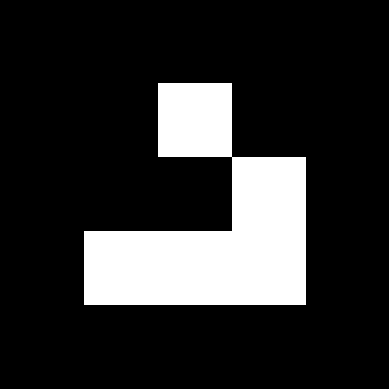

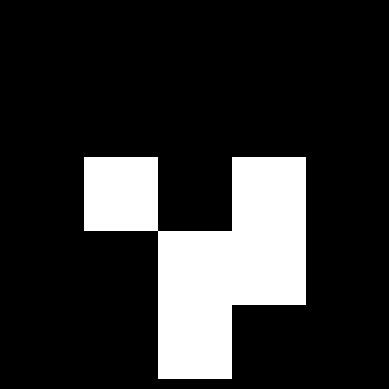

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# 1. 判断棋盘是否有效
def is_valid_board(board):
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    unique_vals = np.unique(board)
    for v in unique_vals:
        if v not in (0, 1):
            return False
    return True

# 2. 生命游戏单步更新（环绕边界）
def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("无效的生命游戏棋盘，必须是仅含0/1的二维numpy数组")
    m, n = board.shape
    neighbors = (
        np.roll(board, (1, 0), axis=(0, 1)) +
        np.roll(board, (-1, 0), axis=(0, 1)) +
        np.roll(board, (0, 1), axis=(0, 1)) +
        np.roll(board, (0, -1), axis=(0, 1)) +
        np.roll(board, (1, 1), axis=(0, 1)) +
        np.roll(board, (1, -1), axis=(0, 1)) +
        np.roll(board, (-1, 1), axis=(0, 1)) +
        np.roll(board, (-1, -1), axis=(0, 1))
    )
    new_board = np.zeros_like(board)
    alive = board == 1
    new_board[alive & ((neighbors == 2) | (neighbors == 3))] = 1
    new_board[(board == 0) & (neighbors == 3)] = 1
    return new_board

# 3. 绘制棋盘
def draw_gol_board(board):
    plt.figure()
    plt.imshow(board, cmap="gray", vmin=0, vmax=1)
    plt.xticks([])
    plt.yticks([])
    plt.axis("off")
    plt.show()

# ========== 测试代码 ==========
if __name__ == "__main__":
    # 滑翔机
    glider = np.array([
        [0, 1, 0],
        [0, 0, 1],
        [1, 1, 1]
    ])
    board = np.zeros((5, 5), dtype=int)
    board[1:4, 1:4] = glider

    print(is_valid_board(board))
    draw_gol_board(board)
    board = gol_step(board)
    draw_gol_board(board)


In [2]:
import pandas as pd

df = pd.read_csv("D:/Iris.csv")


print("数据形状：", df.shape)
print("\n数据信息：")
print(df.info())
print("\n各类别的数量：")
print(df["Species"].value_counts())


df.loc[34, ["SepalLengthCm","SepalWidthCm","PetalLengthCm","PetalWidthCm","Species"]] = [4.9, 3.1, 1.5, 0.2, "Iris-setosa"]


df.loc[37, ["SepalLengthCm","SepalWidthCm","PetalLengthCm","PetalWidthCm","Species"]] = [4.9, 3.6, 1.4, 0.1, "Iris-setosa"]


df["Petal.Ratio"] = df["PetalLengthCm"] / df["PetalWidthCm"]

df["Sepal.Ratio"] = df["SepalLengthCm"] / df["SepalWidthCm"]


df.to_csv("D:/iris_corrected.csv", index=False)
print("\n已保存文件到 D:/iris_corrected.csv")


group_result = df.groupby("Species")[["Petal.Ratio","Sepal.Ratio"]].agg(["mean","median","min","max","std"])
print("\n====分组统计结果====")
print(group_result)


数据形状： (150, 6)

数据信息：
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB
None

各类别的数量：
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

已保存文件到 D:/iris_corrected.csv

====分组统计结果====
                Petal.Ratio                                     Sepal.Ratio  \
                       mean    median       min   max       std        mean   
Species                                                                       
Iris-setosa        6.908000  7.000000  2.666667  15.0  2.854545    1.470188   